# 06. A chemical plant run in six different ways: are the links between sensors straight or curved?

**The question.** Notebooks 02 and 04 found that on the standard simulated chemical plant (Tennessee Eastman), each sensor can be predicted from the others about as well by a straight-line model as by a flexible one. That plant is always run the same way. A real plant is run in several ways (more or less product, a different product mix). This notebook asks: **when the plant is run in six different ways, do the links between sensors become curved?**

**The data.** Reinartz, Kulahci and Ravn (2021) simulated the same plant in six *modes*. A mode is one way of running the plant: a target product mix and a target production rate. They published the readings at data.dtu.dk (record 13385936): 52 sensors, one reading every 3 minutes, 100 hours per run.

**Words used here.**

- **Straight share**: how much of a sensor's movement a straight-line model can predict from the other sensors, on runs the model never saw. 1 means all of it, 0 means none.
- **Curved share**: how much *more* a flexible model predicts, on the same unseen runs. This is the number the project's decision rule looks at. It is quoted in *points*: +3 points means the flexible model explains 3 percentage points more of the movement.
- **Range**: every number comes with a 90% range, found by redoing the sum many times with the runs drawn at random (with repeats). If the range is wide, the number is not pinned down.
- **Pooled**: all six modes put together in one data set.

**The rule this feeds** (fixed before this data was opened): GO if the pooled, same-moment curved share's whole 90% range lies above +3 points on either this data or the Cranfield rig (notebook 05); NO-GO if both stay at or near zero. This notebook reports which side of +3 points the range falls on. It does not make the call.

**Layout** (as in notebook 05): 1 the files, 2 are these the same sensors, 3 two things found before measuring, 4 which runs are fitted on and which are held out, 5 the outlier-run check, 6 the go/no-go measure, 7 sensor by sensor, 8 why the pooled number is so small, 9 inside each mode, 10 the sensors that are curved inside a mode, 11 summary. Detectors are not in this notebook yet; they come second and need faulty runs that have not been downloaded.

## 1. The files, and what was downloaded

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import warnings
import pandas as pd

from adlab import data, explore, multimode, plots, structure

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", explore.tidy)
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)

multimode.download()          # about 0.5 GB out of 143 GB, about 17 minutes the first time; nothing if already there
print("Megabytes transferred per mode:", {m: multimode.index(m)["megabytes_transferred"] for m in multimode.MODES})
multimode.mode_table()

Megabytes transferred per mode: {1: 80.4, 2: 76.5, 3: 82.4, 4: 70.1, 5: 76.4, 6: 81.9}


,product flow (XMEAS(17)),reactor pressure (XMEAS(7)),reactor level (XMEAS(8)),reactor temperature (XMEAS(9)),% G in product (XMEAS(40)),% H in product (XMEAS(41))
mode 1,22.889,2800.002,64.996,122.9,53.797,43.938
mode 2,22.729,2799.995,64.997,124.2,11.663,85.611
mode 3,18.039,2800.002,64.998,121.9,90.087,8.154
mode 4,36.041,2799.999,65.001,128.2,53.35,43.547
mode 5,23.549,2799.998,65.004,124.6,11.659,85.534
mode 6,20.197,2799.991,65.004,123,90.067,8.165


**What this shows.** The six files are about 24 GB each (143 GB in all). Each holds thousands of runs, nearly all with faults. Only the fault-free runs and the runs that move from one mode to another were needed, so the loader asks the server for just those byte ranges: about 0.5 GB in total. The data sits in `data/raw/tep_multimode/` and is not committed.

The table shows what sets the modes apart. Modes 1, 2 and 3 make three different mixes of the two products G and H: about half and half, mostly H, and mostly G. Modes 4, 5 and 6 make the same three mixes at a higher production rate (much higher in mode 4, a little higher in modes 5 and 6). Reactor pressure and level are held at the same targets in every mode.

## 2. Are these the same sensors as the plant in the earlier notebooks?

The task notes said mode 1 is "the standard plant", so its readings should look like the fault-free runs used in notebooks 02 to 04 (the Rieth runs). The table compares the two, sensor by sensor. "Gap, in Rieth spreads" is how far apart the two averages are, counted in units of how much the sensor normally wobbles in the Rieth runs.

In [2]:
check = multimode.column_check()
print("Sensors whose average differs from the Rieth runs by more than one spread:",
      int((check["gap, in Rieth spreads"].abs() > 1).sum()), "of", len(check))
check.loc[["XMEAS(1)", "XMEAS(2)", "XMEAS(17)", "XMV(1)", "XMV(2)", "XMEAS(7)", "XMEAS(8)", "XMEAS(9)", "XMEAS(19)", "XMEAS(20)"]]

Sensors whose average differs from the Rieth runs by more than one spread: 36 of 52


,what it measures,"average, mode 1 here","average, Rieth runs","gap, in Rieth spreads",spread here / spread in Rieth
sensor,,,,,
XMEAS(1),A feed (stream 1),0.267,0.25,0.532,0.18
XMEAS(2),D feed (stream 2),3654.555,3663.089,-0.247,0.543
XMEAS(17),Stripper underflow,22.889,22.956,-0.109,0.186
XMV(1),D feed flow,62.888,63.035,-0.251,0.181
XMV(2),E feed flow,53.182,53.984,-1.679,0.236
XMEAS(7),Reactor pressure,2800.002,2705.62,12.121,0.126
XMEAS(8),Reactor level,64.996,74.996,-18.342,0.914
XMEAS(9),Reactor temperature,122.9,120.4,130.783,0.575
XMEAS(19),Stripper steam flow,4.745,232.151,-20.657,0.105


**What this shows.** The sensors are the same and in the same order: the feed flows and the product flow (first five rows) are within a spread or two of the Rieth runs. But **mode 1 is not run at the same conditions as the Rieth plant**. Reactor pressure is held at 2800 kPa here against about 2706 there, reactor level at 65% against 75%, reactor temperature at 122.9 against 120.4 degrees, and the steam flow to the stripper is almost shut off. In all, 36 of the 52 sensors sit more than one spread away from their Rieth average. Most sensors also wobble much less here (last column: often a fifth as much).

So the check asked for in section 9 ("inside mode 1 the result should match notebook 04") can only be loose. The curved share should be about zero in both. The straight share need not be the same, because a plant that wobbles less gives a straight model less to predict.

## 3. Two things found before measuring

**First: how many different runs are there?** The files store 60 fault-free runs per mode. Before using them, each was compared with every other, byte for byte.

In [3]:
multimode.copies_table()

,fault-free runs stored,different simulations,copies of each,the different ones are stored runs,transition runs
mode 1,60,5,"12, 12, 12, 12, 12","1, 2, 3, 4, 5",18
mode 2,60,5,"12, 12, 12, 12, 12","1, 2, 3, 4, 5",14
mode 3,60,5,"12, 12, 12, 12, 12","1, 2, 3, 4, 5",20
mode 4,60,5,"12, 12, 12, 12, 12","1, 2, 3, 4, 5",7
mode 5,60,5,"12, 12, 12, 12, 12","1, 2, 3, 4, 5",14
mode 6,60,5,"12, 12, 12, 12, 12","1, 2, 3, 4, 5",20


**What this shows.** Only **5 of the 60 fault-free runs in each mode are different simulations**. Each is stored 12 times under different names. If all 60 had been used, a model would have been tested on exact copies of runs it was fitted on, and every result would have looked better than it is. From here on, each mode has 5 runs: 30 fault-free runs in all. A test in `tests/test_multimode.py` guards this.

The runs that move between modes ("transition runs") are all different from each other. There are 93, unevenly spread over the modes.

**Second: do runs start cleanly?** The next table counts, hour by hour, how many sensors sit well away from where they later settle.

In [4]:
multimode.start_up_table()

sensors more than half a spread from their later level,hour 1,hour 2,hour 5,hour 10,hour 20
mode 1,12,11,9,6,0
mode 2,20,14,13,5,13
mode 3,6,9,1,2,7
mode 4,6,9,3,8,13
mode 5,12,22,14,12,1
mode 6,23,14,5,1,1


**What this shows.** Added over the six modes, the count is 79 in each of the first two hours, 45 in hour 5, and about 35 at hours 10 and 20. So the first few hours stand out, though not sharply: with only 5 runs to average over, slow wander alone keeps the count at about 35 at any hour. Every run starts from the same stored state and needs a few hours to settle. **The first 5 hours (100 readings) of every run are left out** of everything below, at a cost of 5% of the data. This was decided from this table, before any curved share was computed.

## 4. Which runs are fitted on, and which are held out

*This section was written before any curved share was computed.*

A model is only judged on runs it never saw. The plan:

- **Runs used:** the 30 different fault-free runs, 5 per mode, each without its first 5 hours (1,900 readings per run, 57,000 in all).
- **Five rounds.** In round 1, run 1 of every mode is held out (6 whole runs) and the models are fitted on runs 2 to 5 of every mode (24 runs). Round 2 holds out run 2 of every mode, and so on. Every run is held out exactly once, and scored only by models that never saw it.
- **Every mode is on both sides, every round.** No model is asked about a mode it was never shown.
- **Ranges** come from drawing the 30 runs at random with repeats, 500 times.
- **Same moment** means a sensor is predicted from the other 51 sensors' readings at that same instant. This is the go/no-go measure.
- **Beside it:**
  - *Mode told to the straight model*: the straight model is also told which mode the plant is in, so it can give each mode its own level (as in notebook 05). If the curved share drops, the curve was just the modes sitting at different levels.
  - *Lags*: the models also see the other sensors' readings from 1, 2, 5 and 10 readings earlier (3 to 30 minutes), the same lags as on the standard plant in notebook 04. Supporting numbers only.
  - *With runs that move between modes added*: the 93 transition runs are added to both sides. A transition that takes 10, 20, 30 or 40 hours is held out in round 1, 2, 3 or 4.
  - *Inside each mode*: the same five rounds using one mode's 5 runs only.

In [5]:
multimode.split_table()

,held out and scored,fitted on,readings held out,readings fitted on
round 1,run 1 of every mode (6 runs),"runs 2, 3, 4, 5 of every mode (24 runs)",11400,45600
round 2,run 2 of every mode (6 runs),"runs 1, 3, 4, 5 of every mode (24 runs)",11400,45600
round 3,run 3 of every mode (6 runs),"runs 1, 2, 4, 5 of every mode (24 runs)",11400,45600
round 4,run 4 of every mode (6 runs),"runs 1, 2, 3, 5 of every mode (24 runs)",11400,45600
round 5,run 5 of every mode (6 runs),"runs 1, 2, 3, 4 of every mode (24 runs)",11400,45600


**What this shows.** The five rounds, as planned. Nothing in this split was changed after seeing results.

## 5. Does one run dominate? (the outlier-run rule)

The rule, fixed in advance: if a single run holds more than half of any sensor's movement, report results with and without that run and headline the version without. The table shows, for the sensors where one run counts most, the largest share of that sensor's movement held by a single run. With 30 runs, an even share would be about 0.03.

In [6]:
runs = multimode.split()
structure.movement_by_run(runs["runs"], data.TEP_CHANNELS, runs["names"]).sort_values("largest share", ascending=False).head(6)

,largest share,run,even share
sensor,,,
XMV(8),0.161,"mode 4, run 1",0.033
XMEAS(4),0.161,"mode 4, run 2",0.033
XMV(4),0.161,"mode 4, run 5",0.033
XMV(7),0.154,"mode 4, run 1",0.033
XMEAS(17),0.149,"mode 4, run 1",0.033
XMEAS(18),0.142,"mode 4, run 1",0.033


**What this shows.** No run comes near one half. The largest share is about 0.16. **The rule is not triggered**, so all 30 runs are used and there is only one version of each result.

The top rows are all mode 4 runs, and all flow sensors. That is not one odd run: mode 4 makes product much faster than the other modes, so its five runs together hold most of the flow sensors' movement, about 0.16 each.

## 6. The go/no-go measure, and the versions beside it

The first row is the go/no-go measure. The rows below are the versions listed in section 4. The straight share is on a scale of 0 to 1. The curved share is given in points (hundredths of that scale), because here it is a small fraction of one point. The first time, this cell takes about an hour and a half (it fits about 250 pairs of models for each row); after that the answers are read from `results/cache`.

In [7]:
pooled = multimode.measures()
multimode.measure_table(pooled)

,straight share,"straight, low","straight, high","curved share, points","curved low, points","curved high, points",sensors gaining over 5 points,sensors gaining over 10 points,held-out runs,held-out readings
measure,,,,,,,,,,
same moment (the go/no-go measure),0.898,0.896,0.9,0.068,0.044,0.096,0,0,30,57000
"same moment, mode told to the straight model",0.899,0.897,0.901,0.027,0.013,0.044,0,0,30,57000
+ 1 back,0.899,0.896,0.901,0.049,0.034,0.067,0,0,30,56970
"+ 1, 2 back",0.899,0.897,0.902,0.031,0.022,0.041,0,0,30,56940
"+ 1, 2, 5 back",0.9,0.897,0.902,0.025,0.017,0.033,0,0,30,56850
"+ 1, 2, 5, 10 back",0.9,0.897,0.902,0.019,0.011,0.026,0,0,30,56700
"same moment, with runs that move between modes added",0.928,0.926,0.93,0.407,0.334,0.505,2,0,123,233700


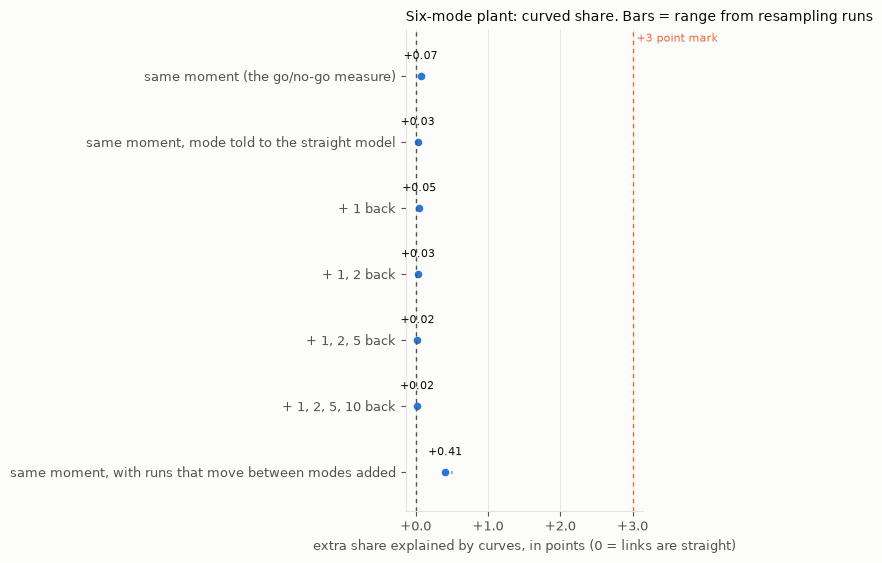

In [8]:
plots.curved_share(pooled, title="Six-mode plant: curved share. Bars = range from resampling runs", mark=0.03, points=True);

**What this shows.**

- **The go/no-go measure: curved share +0.07 points, range +0.04 to +0.10 points.** The whole range lies **below +3 points**, by a wide margin, and is close to zero. The straight share is 0.90 (0.896 to 0.900). No sensor gains more than 10 points from curves; none gains more than 5.
- **Mode told to the straight model:** +0.03 points (+0.01 to +0.04). About half of the already tiny curved share was level differences between modes.
- **Lags:** +0.05, +0.03, +0.02 and +0.02 points as more history is added. Lags do not reveal any hidden curvature; they shrink it.
- **With the runs that move between modes added:** +0.41 points (+0.33 to +0.50). Larger, but still wholly below +3 points. Two sensors gain more than 5 points, none more than 10.

In the plot, the dashed line marks +3 points. Every bar sits far to the left of it.

On this data the pooled measure is on the "at or near zero" side of the rule. Section 8 explains why that number has to be read with care.

## 7. Sensor by sensor

The same measure, one sensor at a time, most curved first. The last two columns repeat it with the mode told to the straight model.

In [9]:
by_sensor = multimode.sensor_table(pooled[multimode.SAME_MOMENT])
told = multimode.sensor_table(pooled[multimode.TOLD])
pd.concat([by_sensor, told[["straight", "curved"]].add_suffix(", mode told")], axis=1).head(12)

,what it measures,straight,curved,curved_low,curved_high,"straight, mode told","curved, mode told"
sensor,,,,,,,
XMEAS(15),Stripper level,0.091,0.031,0.019,0.044,0.121,0.012
XMEAS(7),Reactor pressure,0.863,0.004,0.003,0.005,0.872,0.003
XMEAS(12),Separator level,0.023,0.001,0,0.003,0.027,0
XMEAS(20),Compressor work,0.996,0.001,0.001,0.002,0.998,0
XMV(11),Condenser cooling water flow,0.997,0.001,0,0.001,0.997,0.001
XMV(5),Compressor recycle valve,1,0,0,0,1,0
XMEAS(29),Purge gas: % of component A,0.997,0,0,0,0.997,0
XMEAS(40),Product: % of component G,1,0,0,0,1,0
XMEAS(23),Reactor feed: % of component A,0.99,0,0,0,0.99,0


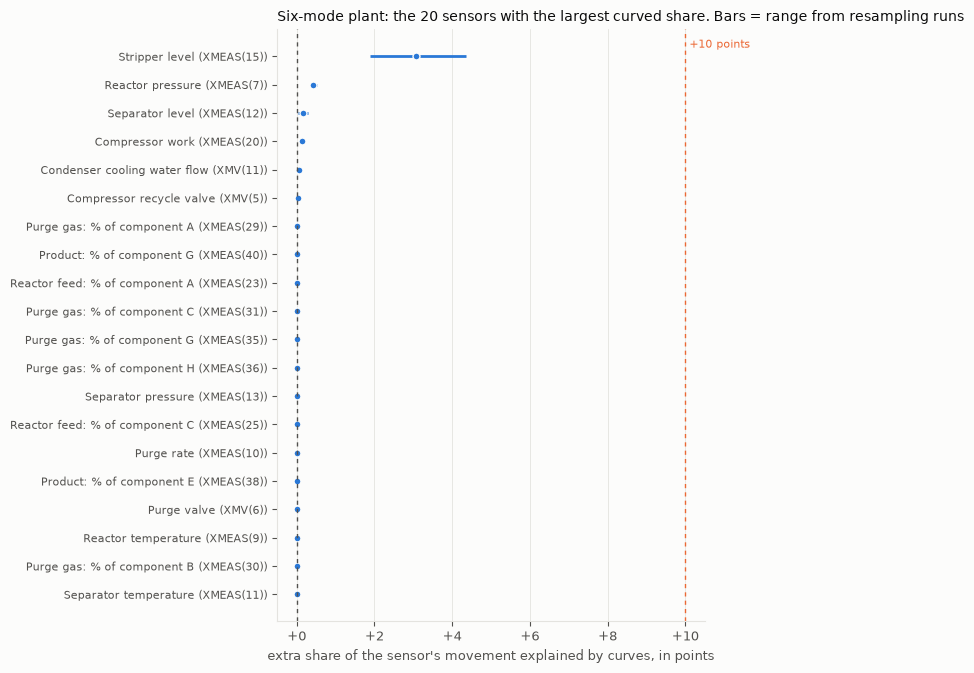

In [10]:
plots.curved_by_sensor(by_sensor.head(20), "Six-mode plant: the 20 sensors with the largest curved share. Bars = range from resampling runs",
                       low="curved_low", high="curved_high");

**What this shows.** One sensor stands out a little: the **stripper level gains about 3 points** from curves (range 1.9 to 4.4), falling to about 1 point once the mode is told. Everything else gains less than half a point. Since no sensor gains over 10 points in the pooled data, there is nothing to plot here under the "over 10 points" rule; section 10 does the plots for the sensors that pass it inside a single mode.

Look at the straight column. Most sensors are predicted almost perfectly (0.99 or more). A few are barely predicted at all (the three tank levels, at 0.00 to 0.09). Section 8 explains this split.

## 8. Why the pooled number is so small: nearly all the movement is the gap between modes

*This table was added after seeing the results in sections 6 and 7, to explain them. No setting was chosen with it.*

In the pooled data a sensor moves for two reasons: the plant is in a different mode (a big jump), or it wanders a little inside a mode. The table gives, for each sensor, the share of its movement that is the gap between modes.

In [11]:
between = multimode.between_modes_share()
share = between["share of movement that is between modes"]
print(f"Sensors that move at all: {share.notna().sum()}. For {int((share > 0.99).sum())} of them, over 99% of the movement "
      f"in the pooled data is the gap between modes. For {int((share < 0.5).sum())}, under half is.")
between.head(7)

Sensors that move at all: 51. For 41 of them, over 99% of the movement in the pooled data is the gap between modes. For 5, under half is.


,what it measures,share of movement that is between modes
sensor,,
XMEAS(7),Reactor pressure,0
XMEAS(8),Reactor level,0
XMEAS(12),Separator level,0
XMEAS(15),Stripper level,0.003
XMEAS(19),Stripper steam flow,0.276
XMEAS(37),Product: % of component D,0.546
XMEAS(25),Reactor feed: % of component C,0.966


**What this shows.** For 41 of the 51 sensors that move, more than 99% of the movement in the pooled data is the gap between modes. The six modes are six tight, widely separated patches.

That matters for how to read section 6:

- A straight model that reads 51 other sensors has more than enough freedom to hit six separate patches exactly, **whatever shape the six patches make**. So on this data the pooled measure could not show a curve between modes even if there were one. A near-perfect straight share (0.99+) for most sensors is the result of having only six modes, not evidence that the plant is straight between them.
- The sensors at the top of the table (the three tank levels and reactor pressure) are held at the same target in every mode. They have no gap between modes, so only their small wander is left to predict. For the three levels a model predicts almost none of it, which is why their straight shares in section 7 are so low.

Two of the measures in this notebook do not have this limit. The runs that move between modes pass through the space between the patches, so a bent path would show there: that row gave +0.41 points. And the measure inside each mode, next, looks only at the wander.

## 9. Inside each mode

The same measure using one mode's 5 runs at a time: each run held out in turn, predicted by models fitted on the other 4. With only 5 runs the ranges are rough. The last table puts mode 1 beside the standard plant from notebook 04, as a check that the data is read correctly.

In [12]:
inside = multimode.within_modes()
multimode.measure_table(inside)

,straight share,"straight, low","straight, high","curved share, points","curved low, points","curved high, points",sensors gaining over 5 points,sensors gaining over 10 points,held-out runs,held-out readings
measure,,,,,,,,,,
mode 1,0.267,0.258,0.273,-0.873,-0.918,-0.825,0,0,5,9500
mode 2,0.274,0.27,0.278,-0.787,-0.845,-0.732,0,0,5,9500
mode 3,0.284,0.279,0.288,0.543,0.495,0.613,2,1,5,9500
mode 4,0.319,0.307,0.328,-0.903,-4.128,-0.755,0,0,5,9500
mode 5,0.305,0.291,0.317,-0.79,-0.915,-0.704,0,0,5,9500
mode 6,0.343,0.294,0.361,1.858,1.676,2.561,5,3,5,9500


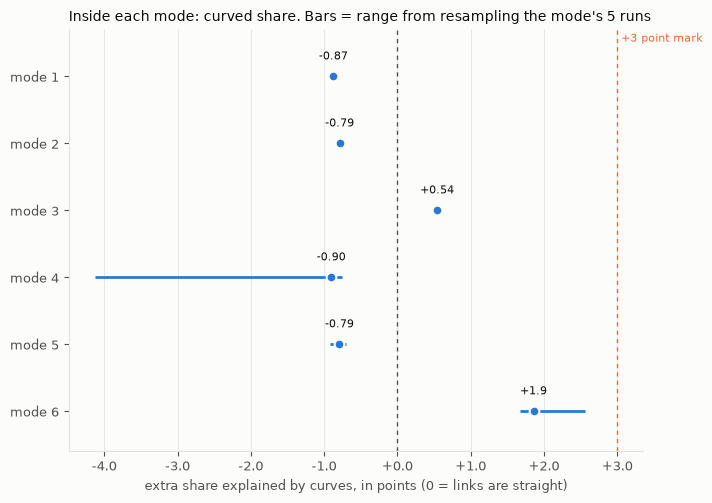

In [13]:
plots.curved_share(inside, title="Inside each mode: curved share. Bars = range from resampling the mode's 5 runs", mark=0.03, points=True);

In [14]:
multimode.standard_plant_check(inside)

,straight share,"straight, low","straight, high","curved share, points","curved low, points","curved high, points",sensors gaining over 5 points,sensors gaining over 10 points,held-out runs,held-out readings
measure,,,,,,,,,,
"standard plant (notebook 04, 20 runs)",0.517,0.508,0.526,-0.536,-0.581,-0.489,0,0,20,10000
mode 1 here (5 runs),0.267,0.258,0.273,-0.873,-0.918,-0.825,0,0,5,9500


**What this shows.**

- **Modes 1, 2, 4 and 5: curved share about −0.8 to −0.9 points.** Slightly below zero means the flexible model did a little *worse* than the straight one on unseen runs: there is no curve to find, and it fitted noise instead. Mode 4's range reaches down to −4 points because of one sensor in one run (the D feed valve, which hardly moves there, so a small miss counts as a large share).
- **Mode 3: +0.5 points (+0.5 to +0.6). Mode 6: +1.9 points (+1.7 to +2.6).** Both ranges are wholly below +3 points. These averages hide a few strongly curved sensors: one sensor gains over 10 points in mode 3 and three do in mode 6. Section 10 looks at them.
- Inside a mode the straight share is only 0.27 to 0.34. With the gaps between modes gone, most of what is left is noise that nothing predicts.
- **The check against notebook 04.** The standard plant there gave a curved share of −0.5 points (−0.6 to −0.5); mode 1 here gives −0.9 points (−0.9 to −0.8). Both are about zero and slightly negative, as expected. The straight shares differ (0.52 there, 0.27 here), which fits section 2: mode 1 here is held at different conditions and wobbles less. The check passes in the loose sense described in section 2.

## 10. The sensors that are curved inside a mode

For each sensor that gains more than 10 points from curves inside one mode: its shares, the one other sensor that says most about it, and how much of the time it sits exactly at its highest value. Each is then plotted against that other sensor, using that mode's readings only. (The pooled data has no sensor over 10 points, so the six-panel plot coloured by mode, as in notebook 05 section 9, has nothing to show. *This inside-mode table and plot were added after seeing section 9.*)

what it measures straight curved  \
mode   sensor                                                           
mode 3 XMV(5)                Compressor recycle valve    0.392  0.603   
mode 6 XMEAS(22)  Separator cooling water outlet temp    0.662  0.178   
       XMV(1)                             D feed flow    0.301  0.175   
       XMV(5)                Compressor recycle valve    0.384  0.582   

                 curved_low curved_high best single predictor  \
mode   sensor                                                   
mode 3 XMV(5)          0.59       0.619               XMV(11)   
mode 6 XMEAS(22)      0.153        0.57               XMV(11)   
       XMV(1)         0.117       0.271                XMV(2)   
       XMV(5)         0.563       0.608               XMV(11)   

                                which measures  \
mode   sensor                                    
mode 3 XMV(5)     Condenser cooling water flow   
mode 6 XMEAS(22)  Condenser cooling water flow   
       XMV(1)                      E feed flow   
       XMV(5)     Condenser cooling water flow   

                 share of time at its highest value  
mode   sensor                                        
mode 3 XMV(5)                                 0.822  
mode 6 XMEAS(22)                                  0  
       XMV(1)                                 0.428  
       XMV(5)                                 0.812

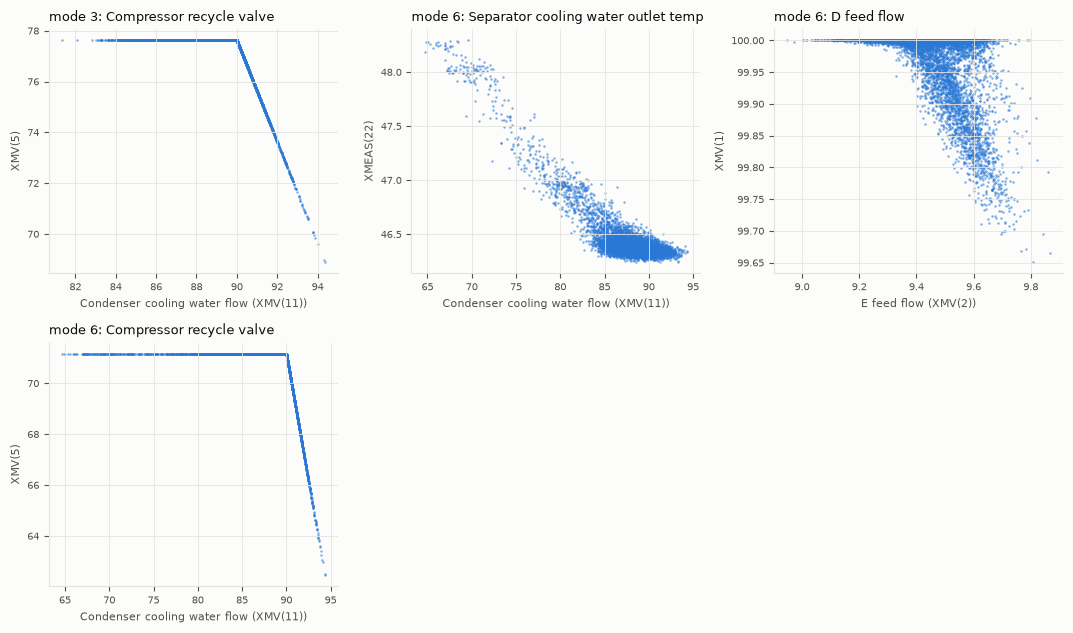

In [15]:
curved_inside = multimode.within_curved(inside)
display(curved_inside)
multimode.within_scatter(curved_inside);

**What this shows.** These are not smooth curves. They are valves hitting a limit.

- **Compressor recycle valve, modes 3 and 6 (gains about 60 points).** It sits at one fixed value about 82% of the time. When the condenser cooling water valve goes above 90%, the recycle valve drops along a perfectly straight line. An exact line with no scatter between two valves can only be a rule written into the plant's control system: one valve takes over when the other runs out of room. The picture is two straight pieces joined at a corner. A single straight line cannot follow a corner; a flexible model can. In modes 1, 2, 4 and 5 this valve never moves at all.
- **D feed valve, mode 6 (gains about 18 points).** The valve is fully open (100%) about 43% of the time and cannot open further. A ceiling again.
- **Separator cooling water temperature, mode 6 (gains about 18 points).** A gentle bend against the same cooling water valve. Its range is wide (15 to 57 points): in one of the five runs that valve travelled about three times further than in the others, so the result leans on that run.

So where curvature does appear in this plant, it is in modes 3 and 6, where the plant is pushed against the limits of its equipment, and it has the form of corners and ceilings in a few valves. It is real and it is large for those few sensors, but it is confined to them. Averaged over all 52 sensors it comes to +0.5 points in mode 3 and +1.9 points in mode 6.

## 11. Summary

**Against the rule.** The go/no-go measure (pooled over six modes, same moment) is a curved share of **+0.07 points, range +0.04 to +0.10**. The whole range is **below +3 points** and close to zero. The versions beside it agree: mode told +0.03 (+0.01 to +0.04); lags +0.02 to +0.05; with transition runs added +0.41 (+0.33 to +0.50); inside single modes −0.9 to +1.9, every range below +3. The call itself is left to the people making it.

**What to keep in mind when reading that number.**

1. **The pooled measure is weak on this data.** With only six modes, and nearly all pooled movement being the gap between modes, a straight model with 51 inputs fits the six patches exactly whatever their shape (section 8). The pooled number mostly says "a straight model can tell which mode the plant is in". The transition-run and inside-mode numbers are the ones that could have shown curvature, and they are small too.
2. **There is real curvature in a few places.** In modes 3 and 6, valves hit their limits and a control rule switches from one valve to another. For those few sensors the gain from curves is large (18 to 60 points). It takes the form of corners and ceilings, not smooth curves (section 10).
3. **Only 5 different fault-free runs per mode exist**, not 60 (section 3). Ranges inside a mode rest on 5 runs and are rough.
4. **Mode 1 is not the plant of notebooks 02 to 04** (section 2). The check against notebook 04 passes loosely: curved share about zero in both.

**Choices, and when they were made.**

- Before measuring: use the 5 different runs per mode; drop the first 5 hours; the five rounds; the lags; how transition runs are held out (sections 3 and 4).
- After seeing results, for explanation only: the between-modes table (section 8) and the inside-mode table and plot (section 10). No threshold or model setting was chosen after seeing results.
- The outlier-run rule was applied and not triggered (section 5).

**Not done yet.** Detectors on this data. They need faulty runs, which have not been downloaded.

## 12. The faulty runs (fetched for the detectors)

*Added on 16 November, before any detector was run on this data.*

For the detectors, one run of each of the 28 faults was fetched for each mode, at full strength: 168 runs, again read straight out of the remote files. A fault is switched on part-way through a run. The time it starts is stored with each run (the field the dataset's Readme calls "idv_init": which faults are on, how strong, and from which hour). The table reads it from every run.

In [16]:
multimode.download_faults()     # about 0.2 GB, about 10 minutes the first time; nothing if already there
multimode.faulty_table()

,faulty runs,stopped early (faults),"readings, fewest","readings, most",fault starts at hour,strength,megabytes transferred
mode 1,28,6,742,2000,30,1,33
mode 2,28,6,736,2000,30,1,33.2
mode 3,28,6,722,2000,30,1,33
mode 4,28,"1, 6, 7",628,2000,30,1,32.2
mode 5,28,6,721,2000,30,1,33.1
mode 6,28,6,716,2000,30,1,33.2


**What this shows.** Every fault, in every mode, starts at **hour 30** and is at full strength. Most runs last the full 100 hours (2,000 readings). Some do not: the simulated plant shut itself down soon after the fault started. Fault 6 (loss of the A feed) does this in every mode, after about 6 to 7 hours of fault. In mode 4, faults 1 and 7 do it too. Those runs are kept: their readings up to the shutdown are still a fault to detect.

One oddity of storage: in mode 4 the runs are stored without the extra first reading at time 0 that the other modes have. The loader allows for this, so in every mode reading number i is taken 3 × (i + 1) minutes into the run (checked below).

**Do the faulty runs share random numbers with the normal runs?** If a faulty run had the same random numbers as one of the 5 normal runs of its mode, the two would be identical until the fault starts. A detector fitted on that normal run would then be scored on a copy of its own training data for the first 30 hours. The next table compares the stretch before the fault (hours 0 to 30) of every faulty run with the same stretch of every normal run of its mode, and with every other faulty run of its mode.

In [17]:
print("Time of the first and last reading after loading (hours):", multimode.alignment_check())
multimode.twin_check()

Time of the first and last reading after loading (hours): {'fault-free first, last': (0.05, 100.0), 'faulty first, last': (0.05, 100.0)}


,faulty runs identical to a normal run before the fault,"closest to a normal run (largest gap, spreads)",pairs of faulty runs identical before the fault,of pairs,"closest two faulty runs (largest gap, spreads)"
mode 1,0,5.024,0,378,4.921
mode 2,0,4.911,0,378,4.984
mode 3,0,6.117,0,378,5.764
mode 4,0,5.814,3,378,0
mode 5,0,4.994,0,378,4.973
mode 6,0,6.193,0,378,5.861


**What this shows.**

- **No faulty run shares random numbers with a normal run.** Before the fault, the closest a faulty run comes to any normal run of its mode is a gap of about 5 to 6 spreads in some sensor. So no faulty run is a copy, before its fault, of a run a detector may be fitted on, and the detectors can be fitted on normal runs as they are.
- **Faulty runs are separate from each other**, except in mode 4, where three pairs are identical before their faults (faults 15 and 17, 16 and 18, 23 and 24). Those pairs share random numbers. They are not normal runs, so no detector is fitted on them. But in the false-alarm check on the hours before the fault, each of those three stretches counts twice.

## 13. Detectors: the design

*Written on 16 November before any detector was run on this data.*

- **Fitted on:** runs 1 to 4 of every mode's 5 different fault-free runs (24 runs), without their first 5 hours, all modes together. Every detector is fitted once on these.
- **Alarm line:** set on run 5 of every mode (6 runs, which fit nothing), using only their readings after hour 30, the same stretch of a run that the faults cover. It is one line for all modes, set so that 1 in 100 of those readings crosses it (matched-window line, as for the other Tennessee Eastman data).
- **Scored:** the 168 faulty runs of section 12, also without their first 5 hours. A reading is labelled faulty if it was taken after hour 30.
- **No twins:** no faulty run shares random numbers with a normal run (section 12), so one fit is enough. No run is scored by a model fitted on it or on a copy of it.
- **Detectors:** the eight used throughout, unchanged, plus the **straight-link detector told the mode** (each sensor predicted by a straight line from the others, with its own level in each mode).
- **Measured:** catch rate at 1 false alarm in 100, with 90% ranges from resampling the faulty runs (and, in the same draws, the 6 line runs). A "win" needs a gap of at least 12 points with a range clear of zero. Reported for all modes together and for each mode.
- **Fixed in advance:** the curved-link detector is compared with the straight-link one in modes 3 and 6 (where section 10 found valves hitting their limits) beside the other four modes. **If the curved-link detector wins by the margin in mode 3 or 6, that is said at the top of section 14.**
- **Also:** false alarms on the faulty runs' own readings before hour 30 (they should be about 1 in 100 if the line carries over), and the kinds of fault.

## 14. Detectors: catch rates

**Fixed in advance (section 13): if the curved-link detector beat the straight-link one by the margin in mode 3 or 6, it would be said here first. It did not, in mode 3, in mode 6, or anywhere (section 15).**

Catch rate at 1 false alarm in 100, with its 90% range, for all 168 faulty runs together and for each mode's 28. One alarm line serves all modes. The first time, scoring takes about 40 minutes; Matrix Profile takes most of it.

In [18]:
from adlab import run
multimode.score()                 # the first time, about 40 minutes; then read from results/cache
reports = {"all modes": multimode.detector_report(), **{f"mode {m}": multimode.detector_report(m) for m in multimode.MODES}}
multimode.per_mode_table(reports)

,all modes,mode 1,mode 2,mode 3,mode 4,mode 5,mode 6
detector,,,,,,,
CUSUM chart,0.10 (0.07-0.26),0.06 (0.01-0.14),0.05 (0.00-0.13),0.11 (0.04-0.21),0.13 (0.07-0.59),0.09 (0.03-0.17),0.14 (0.07-0.52)
Curved-link residual,0.46 (0.41-0.52),0.45 (0.32-0.59),0.43 (0.31-0.57),0.48 (0.34-0.61),0.53 (0.38-0.67),0.43 (0.31-0.58),0.48 (0.35-0.61)
EWMA chart,0.26 (0.20-0.39),0.19 (0.10-0.30),0.19 (0.09-0.32),0.26 (0.15-0.38),0.38 (0.24-1.00),0.22 (0.11-0.35),0.34 (0.21-0.48)
Isolation Forest,0.21 (0.15-0.44),0.13 (0.05-0.32),0.12 (0.04-0.25),0.20 (0.07-0.46),0.46 (0.32-0.93),0.15 (0.06-0.28),0.23 (0.12-0.56)
Matrix Profile,0.32 (0.26-0.39),0.31 (0.19-0.44),0.28 (0.17-0.41),0.29 (0.17-0.41),0.40 (0.27-0.55),0.31 (0.20-0.45),0.35 (0.23-0.48)
PCA (T2 + SPE),0.23 (0.19-0.29),0.19 (0.10-0.30),0.17 (0.08-0.28),0.24 (0.14-0.35),0.31 (0.20-0.44),0.22 (0.12-0.34),0.28 (0.17-0.39)
Rolling z-score,0.24 (0.19-0.32),0.20 (0.10-0.31),0.17 (0.09-0.30),0.27 (0.16-0.39),0.32 (0.21-0.48),0.22 (0.12-0.35),0.29 (0.19-0.45)
Straight-link residual,0.46 (0.41-0.51),0.44 (0.32-0.59),0.43 (0.31-0.57),0.48 (0.34-0.61),0.52 (0.38-0.67),0.43 (0.31-0.57),0.48 (0.35-0.61)
"Straight-link residual, mode told",0.30 (0.25-0.35),0.28 (0.17-0.40),0.31 (0.20-0.43),0.28 (0.16-0.39),0.34 (0.23-0.47),0.31 (0.20-0.42),0.28 (0.16-0.40)


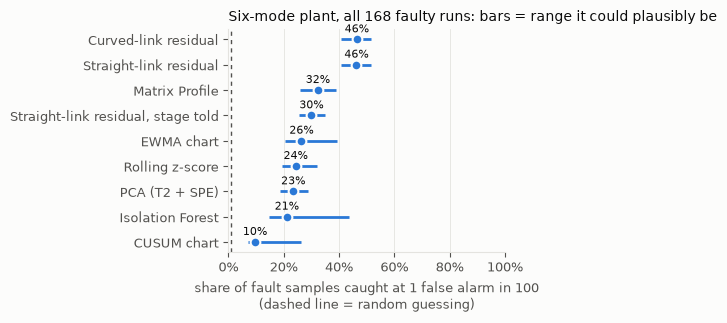

In [19]:
plots.pilot_overall({"all": reports["all modes"]}, titles={"all": "Six-mode plant, all 168 faulty runs"});

**What this shows.**

- **The two link detectors lead, together:** straight-link **0.46** (0.41 to 0.51), curved-link **0.46** (0.41 to 0.52). Next come Matrix Profile at 0.32, the straight-link detector told the mode at 0.30, EWMA 0.26, rolling z-score 0.24, PCA 0.23, Isolation Forest 0.21 and CUSUM 0.10.
- **The order is the same in every mode.** The link detectors catch 0.43 to 0.53 of the faulty readings in each mode, most in mode 4.
- **Telling the straight-link detector the mode makes it worse here** (0.30 against 0.46). I have not worked out why. On the metal etcher, telling the step did not hurt. (*Follow-up round:* section 19 finds the main reason, which is how the detector sets each sensor's error scale.)

## 15. Which detector is ahead, and curved against straight mode by mode

Every pair of detectors over all modes ("ahead" needs a gap of at least 12 points with a range clear of zero), then the curved-link detector minus the straight-link one, for all modes and for each mode.

In [20]:
multimode.told_name(run.verdict_table(reports["all modes"]))

,Curved-link residual,Straight-link residual,Matrix Profile,"Straight-link residual, mode told",EWMA chart,Rolling z-score,PCA (T2 + SPE),Isolation Forest,CUSUM chart
row against column,,,,,,,,,
Curved-link residual,,tie,ahead,ahead,ahead,ahead,ahead,ahead,ahead
Straight-link residual,tie,,ahead,ahead,ahead,ahead,ahead,ahead,ahead
Matrix Profile,behind,behind,,tie,tie,tie,tie,tie,ahead
"Straight-link residual, mode told",behind,behind,tie,,tie,tie,tie,tie,ahead
EWMA chart,behind,behind,tie,tie,,tie,tie,tie,ahead
Rolling z-score,behind,behind,tie,tie,tie,,tie,tie,ahead
PCA (T2 + SPE),behind,behind,tie,tie,tie,tie,,tie,tie
Isolation Forest,behind,behind,tie,tie,tie,tie,tie,,tie
CUSUM chart,behind,behind,behind,behind,behind,behind,tie,tie,


In [21]:
multimode.link_gaps(reports)

,curved minus straight,low,high,verdict
runs scored,,,,
all modes,0.001,-0.001,0.004,tie
mode 1,0.002,-0.001,0.004,tie
mode 2,0.002,0,0.005,tie
mode 3,0,-0.003,0.003,tie
mode 4,0.003,0,0.007,tie
mode 5,0.001,-0.002,0.004,tie
mode 6,0,-0.004,0.005,tie


**What this shows.**

- The two link detectors are **ahead of every other detector**, and tied with each other.
- **Curved minus straight is within half a point of zero in every mode**, with ranges no wider than about ±0.7 points. In mode 3 it is −0.03 points (−0.28 to +0.29), in mode 6 −0.00 points (−0.39 to +0.48), and in the other four modes +0.09 to +0.32 points. **A tie everywhere**, by a long way.

This matches section 10. Where the plant's links bend (valves at their limits in modes 3 and 6), only a few sensors are affected, and those bends do not help catch these faults.

## 16. False alarms before the faults

Every faulty run has 25 hours of normal readings before its fault starts at hour 30 (after the first 5 hours are left out). If the one alarm line carries over from the 6 line runs to these runs, about 1 in 100 of those readings should cross it.

In [22]:
multimode.before_fault()

,false alarms before the fault,false alarms after the fault,runs with over 0.05 before the fault,runs
detector,,,,
Rolling z-score,0.011,NaN,13,168
EWMA chart,0.01,NaN,11,168
CUSUM chart,0,NaN,0,168
PCA (T2 + SPE),0.01,NaN,4,168
Isolation Forest,0.008,NaN,6,168
Matrix Profile,0.004,NaN,2,168
Straight-link residual,0.015,NaN,0,168
Curved-link residual,0.015,NaN,0,168
"Straight-link residual, mode told",0.012,NaN,1,168


**What this shows.** **The line carries over.** Before the faults, false alarms are 0.000 to 0.015, close to the 0.01 the line is set for. The link detectors are a little high (0.015) but have no run with more than 5% of its readings over the line. The rolling z-score has 13 such runs out of 168, and EWMA 11. (In mode 4, three pairs of runs share these stretches; see section 12.) There are no readings "after the fault": every fault stays on to the end of its run.

## 17. Kinds of fault

Each detector's catch rate on each of the 28 faults (all modes together). Then the families of checks and a label, as in earlier notebooks: *single sensor* or *many sensors* if level checks catch at least half; *hidden from level checks* if they do not but another family does; *hard for all* if nothing catches half.

In [23]:
display(multimode.told_name(run.fault_table(reports["all modes"])))
multimode.fault_kinds()

,Curved-link residual,Straight-link residual,Matrix Profile,"Straight-link residual, mode told",EWMA chart,Rolling z-score,PCA (T2 + SPE),Isolation Forest,CUSUM chart
kind of fault,,,,,,,,,
IDV(1),0.99,0.99,0.99,0.99,0.99,0.99,0.99,0.24,0.39
IDV(10),0.45,0.44,0.04,0.02,0.08,0.04,0.04,0.05,0.01
IDV(11),0.3,0.29,0.67,0.68,0.32,0.38,0.3,0.11,0.01
IDV(12),0.38,0.36,0.66,0.03,0.42,0.44,0.45,0.44,0.3
IDV(13),0.78,0.78,0.88,0.42,0.88,0.87,0.85,0.8,0.65
IDV(14),0.23,0.21,0.22,0.15,0.02,0.01,0.02,0.01,0.01
IDV(15),0.01,0.01,0.01,0.01,0.01,0.01,0.01,0,0.01
IDV(16),0.04,0.05,0.01,0.05,0.02,0.01,0.01,0.01,0.01
IDV(17),0.82,0.81,0.44,0.76,0.28,0.28,0.2,0.13,0.02


,level checks,straight links,curved links,shape in time,sensors moved,kind
kind of fault,,,,,,
IDV(1),0.991,0.994,0.992,0.987,4.8,many sensors
IDV(2),0.532,0.954,0.957,0.532,3.8,many sensors
IDV(3),0.01,0.011,0.011,0.005,0.3,hard for all
IDV(4),0.181,0.181,0.181,0.015,0.2,hard for all
IDV(5),0.171,0.337,0.341,0.049,0.7,hard for all
IDV(6),0.988,1,1,0.996,16.5,many sensors
IDV(7),0.025,1,1,0.222,2.2,hidden from level checks
IDV(8),0.901,0.897,0.858,0.931,6.3,many sensors
IDV(9),0.064,0.038,0.014,0.033,0,hard for all


**What this shows.**

- **Many sensors (easy):** faults 1, 2, 6, 8, 13 and 20. **Single sensor:** fault 24.
- **Hidden from level checks, caught by the link detectors:** faults 7, 11, 12, 17, 18, 19, 23, 25 and 26. These are where the link detectors gain their lead. For example, fault 7 is caught 1.00 by both link detectors against 0.03 by the level checks; fault 23 0.87 against 0.02.
- **Hard for all:** faults 3, 4, 5, 9, 10, 14, 15, 16, 21, 22, 27 and 28. Faults 3, 9 and 15 were hard for all on the standard plant too (notebook 03).

Straight and curved links catch the same faults to within a few points on every kind. Neither has a kind of fault of its own.

## 18. Summary of the detectors

- **Curved-link against straight-link: a tie in all modes and in each mode**, within half a point. That includes modes 3 and 6, where the plant has its few real bends. So there is no win to report, at the top or anywhere.
- The two link detectors lead every other detector by 14 points or more (0.46 against 0.32 for Matrix Profile, the next best).
- The one alarm line, set on 6 normal runs over the hours after hour 30, carries over: false alarms before the faults are about 1 in 100.
- Settings fixed before scoring: the fit runs, the line runs, the labels after hour 30, and dropping the first 5 hours. No setting was chosen after seeing results.

## 19. Follow-up: why telling the mode made the straight-link detector worse

*Added in the follow-up round, after all results. Report only: no detector is changed or added.*

**The idea checked** (fixed before computing): without the mode, the straight model has to lean on strong cross-sensor links to tell the six modes apart, and faults break those links; told the mode, it leans on the weaker links inside a mode. Compared for the straight-link detector fitted on the 24 fit runs, without and with the mode:

- the size of each sensor's cross-sensor coefficients (summed, in standardised units);
- the spread of each sensor's held-out errors, which sets its error scale and so its alarm line;
- on the faulty readings, how many sensors are over their own line, and how large the largest surprise is.

In [24]:
from adlab import followup
display(followup.mode_told_summary())
folds = followup.mode_told_folds()
display(folds["blocks"])
display(folds["spreads"])
followup.mode_told_by_sensor().sort_values("error spread, told / none", ascending=False).head(10)

,"median cross-sensor coefficients (summed, per sensor)",median held-out error spread (standardised units),fault readings: median sensors over their own line,fault readings: mean sensors over their own line,fault readings: median largest surprise (1 = the line)
no mode,2.718,0.081,0,2.429,0.984
mode told,1.872,0.3,0,0.529,0.686


,mode mostly held out,its share of the block,rows of that mode left to fit on
block 1,1,0.833,0
block 2,2,0.667,1520
block 3,3,0.5,3040
block 4,5,0.667,1520
block 5,6,0.833,0


,"median held-out error spread, the detector's blocks of time","median held-out error spread, one run of every mode held out"
no mode,0.081,0.016
mode told,0.3,0.016


,"cross-sensor coefficients, no mode","cross-sensor coefficients, mode told","mode levels, spread (told)","error spread, no mode","error spread, mode told","coefficients, told / none","error spread, told / none"
sensor,,,,,,,
XMV(2),1.939,1.151,1.7,0.004,0.214,0.593,55.03
XMEAS(22),2.868,1.819,3.001,0.047,1.006,0.634,21.259
XMEAS(30),2.157,2.083,3.651,0.026,0.544,0.966,21.009
XMEAS(13),2.904,3.017,6.093,0.12,2.51,1.039,20.948
XMEAS(7),89.483,106.544,71.596,1.672,31.396,1.191,18.78
XMV(11),12.256,12.714,2.275,0.117,1.657,1.037,14.167
XMEAS(34),1.938,1.639,2.634,0.048,0.629,0.846,13.042
XMV(4),1.933,1.395,1.748,0.01,0.126,0.722,12.806
XMV(7),1.575,1.274,0.504,0.017,0.208,0.808,12.151


**What this shows.**

- **The coefficients go the way the idea says, but only a little.** Told the mode, a sensor's cross-sensor coefficients add up to less: a median of 1.9 against 2.7 (a median ratio of 0.85 per sensor).
- **The error scale goes the other way, and by much more.** Told the mode, each sensor's held-out errors spread about **four times wider** (median 0.30 against 0.08 standardised units). Each sensor's line is set from those errors, so the told detector's lines are far wider. On the faulty readings it puts 0.5 sensors over their own line on average, against 2.4 without the mode, and its largest surprise is smaller (median 0.69 of the line, against 0.98).
- **Why the errors spread wider: how they are held out.** The detector sets its scale from five blocks of time over the joined fit data, and the fit runs are stored mode by mode, four runs each. So each block holds out most of one mode. Blocks 1 and 5 hold out **all** of modes 1 and 6, and blocks 2 to 4 half to two thirds of a mode. Told the mode, the straight model must then predict a mode whose level it never saw, and its errors balloon. Without the mode, it guesses the mode from the other sensors and does better.
- **The check.** Held out instead one run of every mode at a time (so every mode is always in the fitted part), the two spreads are the same: 0.016 told and 0.016 without the mode. Both are far smaller than under the blocks (0.30 and 0.08).

**So the told detector's 0.30 is mostly an artefact of how its error scale is set, not a property of telling the mode.** The same blocks also widen the plain straight-link detector's scale about five times on this plant, which may cost it catch rate too. A fair test would set both scales with folds that keep every mode. That is a new detector setting, so it is left for later, as the follow-up round asked.

## 20. Round 3: the straight-link detector with balanced folds

*Added in round 3.* Section 19 found that the straight-link detector sets each sensor's error scale on five blocks of time that each hold out most of one mode. Round 3 reruns it, plain and told the mode, with the scale set on **balanced folds**: four folds, each holding out one run of every mode, so every mode is always in the fitted part (defined before computing: `detectors.StraightLinkBalanced`, `StraightLinkStageToldBalanced`). Nothing else changes: the same fit runs, the same line runs, the same faulty runs.

In [25]:
from adlab import followup
followup.balanced_folds_table()

,caught,range,false alarms before the faults,"minus the straight-link (blocks), points",range of that gap
detector,,,,,
Straight-link residual,0.463,0.41-0.51,0.015,0,
"Straight-link residual, mode told",0.3,0.25-0.35,0.012,-16.294,-21.0 to -11.3
"Straight-link residual, balanced folds",0.666,0.61-0.75,0.006,20.34,+16.2 to +27.5
"Straight-link residual, mode told, balanced folds",0.683,0.63-0.76,0.008,21.992,+17.8 to +28.2
Straight forecaster,0.686,0.63-0.75,0.011,22.302,+17.9 to +28.2
LSTM forecaster,0.593,0.53-0.67,0.015,13.092,+8.0 to +19.8
Autoencoder,0.436,0.36-0.55,0.01,-2.637,-9.3 to +9.1


**What this shows. The old blocks of time cost the straight-link detector about 20 points on this plant.** With balanced folds it catches **0.67** of faulty readings instead of 0.46 (+20 points, range +16 to +28), and told the mode **0.68** instead of 0.30. Told the mode, it is now level with the plain one (the 0.30 of section 14 was the scale, as section 19 suspected), and both are level with the straight forecaster (0.69), the best detector on this plant, and above the LSTM (0.59) and the autoencoder (0.44). False alarms before the faults stay under 1 in 100.

So on this plant, a straight model of the links at the same moment does as well as one that uses each sensor's recent past, once its error scale is set fairly. The curved-link detector shares the old blocks of time; it was not rerun, so its tie with the straight-link detector (section 15) compares two detectors under the same handicap.

## Round 4 note: balanced folds

*Added in round 4 (notebook 09, section 13); the cells above are as they were.* Section 20 switched only the straight-link detector to balanced folds. Round 4's fold audit switched every link detector on this plant (the blocks of time left 2 of the 6 modes with nothing in the fitted part). With balanced folds: the **straight-link** detector catches **0.67** (was 0.46), the **curved-link 0.70** (0.46), the straight-link told the mode **0.68** (0.30) and the **kinked-link 0.71** (0.51), now the best simple detector here. Curved minus straight is +3.0 points (+0.7 to +4.7): still a tie. So the lesson of sections 13 to 18 that the straight forecaster's recent history beat the links was mostly this fold problem; it is level with them (0.69).